In [ ]:
from obspy.signal.spectral_estimation import PPSD
import seaborn as sns
import numpy as np
import pandas as pd
from obspy.imaging.cm import pqlx
col=sns.color_palette("bright")

In [ ]:
file = "/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/NPZ_wo_meteo_spectra/NZL_psd.npz"
ppsd = PPSD.load_npz(file)

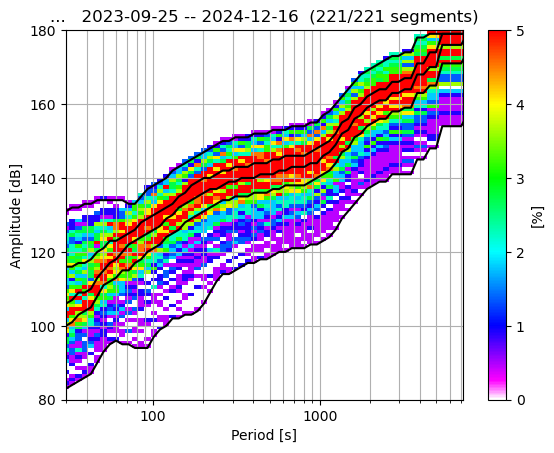

In [17]:
ppsd.plot(period_lim=((30,7200)),show=True,show_coverage=False,
              max_percentage=5,xaxis_frequency=False,show_percentiles=[25,35,50,65,75],cmap=pqlx)

import matplotlib.pyplot as plt 
plt.hist(val_250)

import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import random
import pandas as pd
import os
from pathlib import Path
meteotsunami_count=pd.read_csv("/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/meteotsunami_count.csv")
count=meteotsunami_count.iloc[:,1].tolist()
sta_names=meteotsunami_count.iloc[:,0].tolist()
# CSV file path
csv_file = "distribution_results_SSH.csv"
for station in sta_names:
    file = f"/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/NPZ_w_meteo/{station}_psd.npz"
    ppsd = PPSD.load_npz(file)
    val_250 = ppsd.extract_psd_values(250)
    val_250 = np.array(val_250[0])
    val_120 = ppsd.extract_psd_values(120)
    val_120 = np.array(val_120[0])
    val_800 = ppsd.extract_psd_values(800)
    val_800 = np.array(val_800[0])
    val_2700 = ppsd.extract_psd_values(45*60)
    val_2700 = np.array(val_2700[0])
    combined_array = np.column_stack((val_120,val_250,val_800,val_2700))
    df = pd.DataFrame(combined_array,columns = ["120 s","250 s","800 s", "2700 s"])
    data = combined_array  
    station_name = Path(file).stem[:5]
    # Z-score filtering
    z_scores = np.abs(stats.zscore(data))
    filtered_z = data[(z_scores < 3).all(axis=1)]  # keep rows where all cols < 3 std devs

    print("Original shape:", data.shape)
    print("After Z-score filtering:", filtered_z.shape)

    # Candidate distributions to test
    distributions = ['norm', 'expon', 'lognorm','skewnorm']
    k = 4
    distributions = random.sample(distributions, k)



    results = []
    period_str = None
    for col in range(filtered_z.shape[1]):
        column_data = filtered_z[:, col]
        if col == 0:
            period_str = 120
        elif col == 1:
            period_str = 250
        elif col == 2:
            period_str = 800
        else:
            period_str = 2700


        # ---- Basic statistics ----
        mean = np.mean(column_data)
        std = np.std(column_data)
        skewness = stats.skew(column_data)
        kurtosis = stats.kurtosis(column_data)

        # ---- Distribution fitting ----
        best_fit = None
        best_p = -1
        best_ks = 1
        for dist_name in distributions:
            dist = getattr(stats, dist_name)
            try:
                params = dist.fit(column_data)
                ks_stat, p_val = stats.kstest(column_data, dist_name, args=params)
                if p_val > best_p:

                    best_fit = (dist_name, params, p_val, ks_stat)
                    best_p = p_val
            except Exception:
                continue

        if best_fit is not None:
            if dist_name == "norm":
                dist_name = "normal"
                symbol = "a"
                color = "darkorange"
            elif dist_name == "lognorm":
                dist_name = "log normal"
                symbol = "c"
                color = "darkred"
            elif dist_name == "skewnorm":
                dist_name = "skew normal"
                symbol = "d"
                color = "seagreen"
            elif dist_name == "expon":
                symbol = "g"
                color = "dodgerblue3"

            results.append({
                "Station": station_name,
                "Period": period_str,
                "Mean": mean,
                "StdDev": std,
                "Skewness": skewness,
                "Kurtosis": kurtosis,
                "BestFit": best_fit[0],
                "Params": best_fit[1],
                "p-value": best_fit[2],
                "KS-Stat": best_fit[3],
            

            })
  
        # ---- Plot histogram with best fit ----
        plt.figure()
        plt.hist(column_data, bins=30, density=True, alpha=0.5, label="Data")
        x = np.linspace(min(column_data), max(column_data), 500)
        dist = getattr(stats, best_fit[0])
        pdf_y = dist.pdf(x, *best_fit[1])
        plt.plot(x, pdf_y, 'r-', lw=2, label=f"{best_fit[0]} fit")
        plt.title(f"Column {col+1} Distribution Fit")
        plt.legend()
        plt.show()

    # Convert to DataFrame

    df = pd.DataFrame(results)

    # Append to CSV if exists, otherwise create new

    if os.path.exists(csv_file):
        df.to_csv(csv_file, mode='a', header=False, index=False)
    else:
        df.to_csv(csv_file, index=False)

    print(f"Results saved to {csv_file}")



Original shape: (221, 4)
After Z-score filtering: (216, 4)


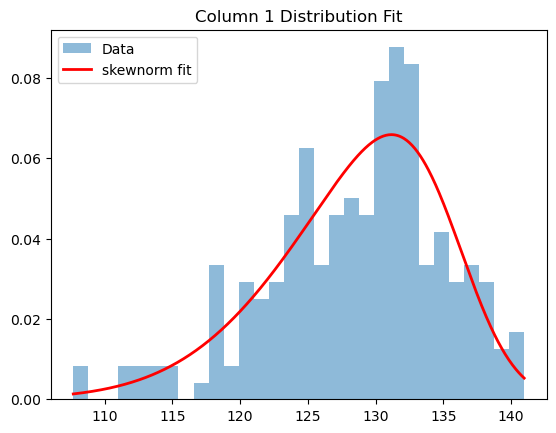

Results saved to distribution_results_SSH.csv


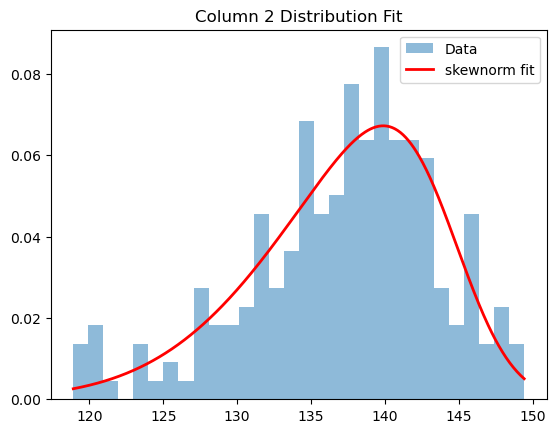

Results saved to distribution_results_SSH.csv


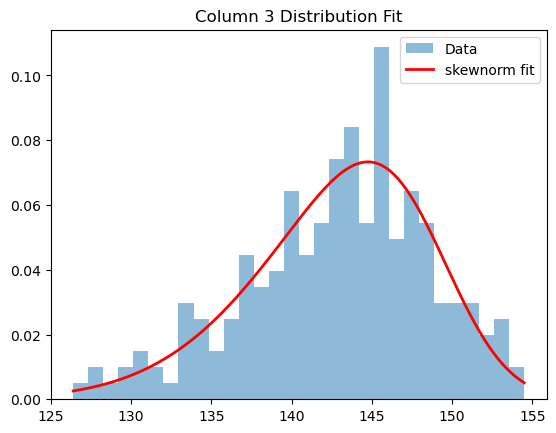

Results saved to distribution_results_SSH.csv


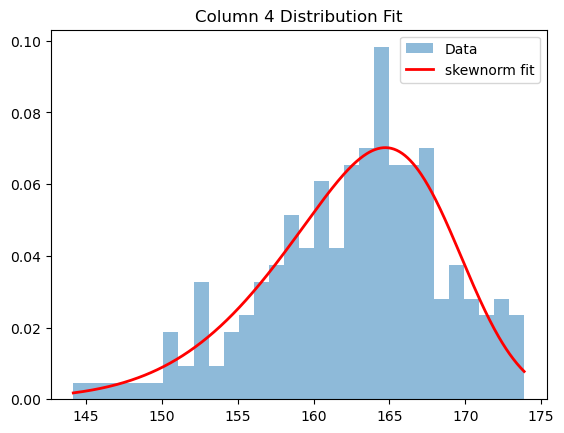

Results saved to distribution_results_SSH.csv


In [18]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import random
import pandas as pd
import os
from pathlib import Path
meteotsunami_count=pd.read_csv("/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/meteotsunami_count.csv")
count=meteotsunami_count.iloc[:,1].tolist()
sta_names=meteotsunami_count.iloc[:,0].tolist()
# CSV file path
csv_file = "distribution_results_SSH.csv"
station="NZL"

file = f"/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/NPZ_wo_meteo_spectra/{station}_psd.npz"
ppsd = PPSD.load_npz(file)
val_250 = ppsd.extract_psd_values(250)
val_250 = np.array(val_250[0])
val_120 = ppsd.extract_psd_values(120)
val_120 = np.array(val_120[0])
val_800 = ppsd.extract_psd_values(800)
val_800 = np.array(val_800[0])
val_2700 = ppsd.extract_psd_values(45*60)
val_2700 = np.array(val_2700[0])
combined_array = np.column_stack((val_120,val_250,val_800,val_2700))
df = pd.DataFrame(combined_array,columns = ["120 s","250 s","800 s", "2700 s"])
data = combined_array  
station_name = Path(file).stem[:5]
# Z-score filtering
z_scores = np.abs(stats.zscore(data))
filtered_z = data[(z_scores < 3).all(axis=1)]  # keep rows where all cols < 3 std devs

print("Original shape:", data.shape)
print("After Z-score filtering:", filtered_z.shape)

# Candidate distributions to test
distributions = ['norm', 'expon', 'lognorm','skewnorm']
k = 4
distributions = random.sample(distributions, k)



results = []
period_str = None
for col in range(filtered_z.shape[1]):
    column_data = filtered_z[:, col]
    if col == 0:
        period_str = 120
    elif col == 1:
        period_str = 250
    elif col == 2:
        period_str = 800
    else:
        period_str = 2700


    # ---- Basic statistics ----
    mean = np.mean(column_data)
    std = np.std(column_data)
    skewness = stats.skew(column_data)
    kurtosis = stats.kurtosis(column_data)

    # ---- Distribution fitting ----
    best_fit = None
    best_p = -1
    best_ks = 1
    for dist_name in distributions:
        dist = getattr(stats, dist_name)
        try:
            params = dist.fit(column_data)
            ks_stat, p_val = stats.kstest(column_data, dist_name, args=params)
            if p_val > best_p:

                best_fit = (dist_name, params, p_val, ks_stat)
                best_p = p_val
        except Exception:
            continue

    if best_fit is not None:
        if dist_name == "norm":
            dist_name = "normal"
            symbol = "a"
            color = "darkorange"
        elif dist_name == "lognorm":
            dist_name = "log normal"
            symbol = "c"
            color = "darkred"
        elif dist_name == "skewnorm":
            dist_name = "skew normal"
            symbol = "d"
            color = "seagreen"
        elif dist_name == "expon":
            symbol = "g"
            color = "dodgerblue3"

        results.append({
            "Station": station_name,
            "Period": period_str,
            "Mean": mean,
            "StdDev": std,
            "Skewness": skewness,
            "Kurtosis": kurtosis,
            "BestFit": best_fit[0],
            "Params": best_fit[1],
            "p-value": best_fit[2],
            "KS-Stat": best_fit[3],
        

        })

    # ---- Plot histogram with best fit ----
    plt.figure()
    plt.hist(column_data, bins=30, density=True, alpha=0.5, label="Data")
    x = np.linspace(min(column_data), max(column_data), 500)
    dist = getattr(stats, best_fit[0])
    pdf_y = dist.pdf(x, *best_fit[1])
    plt.plot(x, pdf_y, 'r-', lw=2, label=f"{best_fit[0]} fit")
    plt.title(f"Column {col+1} Distribution Fit")
    plt.legend()
    plt.show()

    # Convert to DataFrame

    df = pd.DataFrame(results)

    # Append to CSV if exists, otherwise create new

    if os.path.exists(csv_file):
        df.to_csv(csv_file, mode='a', header=False, index=False)
    else:
        df.to_csv(csv_file, index=False)

    print(f"Results saved to {csv_file}")

